# Binary Classification Using Naive Bayes and Support Vector Machine (SVM)
**Course:** Data Science and Analytics (IT-411)  
**Student Name:** Dhruv Sarin  
**Scholar No.:** 23U03...  
**Aim:** To implement and evaluate a Python program to classify two distinct classes using both **Gaussian Naive Bayes** and **Support Vector Machine (SVM)** algorithms, and compare their classification performance metrics, confusion matrices, and ROC-AUC curves.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


### Step 1: Dataset Ingestion and Inspection
We use the **Pima Indians Diabetes Diagnostic Dataset** (fallback to **Breast Cancer Diagnostic** if offline). Both datasets are real-world binary classification problems with continuous physiological predictors.


In [2]:
# Smart loading: Local CSV -> Online GitHub Raw CSV -> Built-in Sklearn dataset
local_path = "../datasets/pima_diabetes.csv" if os.path.exists("../datasets/pima_diabetes.csv") else "dhruv_repo/datasets/pima_diabetes.csv"

if os.path.exists(local_path):
    df = pd.read_csv(local_path)
    X = df.drop('Outcome', axis=1)
    y = df['Outcome']
    dataset_name = "Pima Indians Diabetes (Class 0: Healthy, Class 1: Diabetic)"
    target_names = ["Healthy (0)", "Diabetic (1)"]
else:
    # Built-in fallback guaranteed to work anywhere (even offline/Colab)
    data = load_breast_cancer()
    X = pd.DataFrame(data.data, columns=data.feature_names)
    y = pd.Series(data.target)
    dataset_name = "Breast Cancer Diagnostic (Class 0: Malignant, Class 1: Benign)"
    target_names = ["Malignant (0)", "Benign (1)"]

print(f"Loaded Dataset: {dataset_name}")
print(f"Total Observations: {X.shape[0]} samples")
print(f"Total Predictor Features: {X.shape[1]} features")
print(f"\nClass Distribution:\n{y.value_counts().to_string()}")
X.head()


Loaded Dataset: Pima Indians Diabetes (Class 0: Healthy, Class 1: Diabetic)
Total Observations: 768 samples
Total Predictor Features: 8 features

Class Distribution:
Outcome
0    500
1    268


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


### Step 2: Train-Test Split & Feature Standardization
We split the data into 80% Training and 20% Testing sets using stratified sampling to preserve class ratios.
We apply `StandardScaler` ($z = \frac{x - \mu}{\sigma}$) because SVM computes Euclidean margin distances, which requires zero mean and unit variance.


In [3]:
# 1. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 2. Feature Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Samples: {X_train.shape[0]}")
print(f"Testing Samples:  {X_test.shape[0]}")


Training Samples: 614
Testing Samples:  154


### Step 3: Implement Gaussian Naive Bayes Classifier
Naive Bayes applies Bayes' Theorem with the assumption that features are conditionally independent given the class:
$$P(C_k \mid X) \propto P(C_k) \prod_{j=1}^p P(x_j \mid C_k)$$
For continuous variables, $P(x_j \mid C_k)$ is modeled using a Gaussian (Normal) distribution.


In [4]:
# Initialize and train Gaussian Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# Predictions and class probabilities
y_pred_nb = nb_model.predict(X_test_scaled)
y_prob_nb = nb_model.predict_proba(X_test_scaled)[:, 1]

acc_nb = accuracy_score(y_test, y_pred_nb)
print(f"Naive Bayes Test Accuracy: {acc_nb * 100:.2f}%\n")
print("Classification Report (Naive Bayes):")
print(classification_report(y_test, y_pred_nb, target_names=target_names, digits=4))


Naive Bayes Test Accuracy: 70.78%

Classification Report (Naive Bayes):
              precision    recall  f1-score   support

 Healthy (0)     0.7957    0.7400    0.7668       100
Diabetic (1)     0.5738    0.6481    0.6087        54

    accuracy                         0.7078       154
   macro avg     0.6847    0.6941    0.6878       154
weighted avg     0.7179    0.7078    0.7114       154



### Step 4: Implement Support Vector Machine (SVM) Classifier
SVM finds the optimal separating hyperplane that maximizes the margin between the two classes.
We use the **RBF (Radial Basis Function)** kernel ($K(x, x') = \exp(-\gamma \|x - x'\|^2)$) to capture complex non-linear decision boundaries.


In [5]:
# Initialize and train SVM with RBF kernel and probability estimation
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Predictions and class probabilities
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

acc_svm = accuracy_score(y_test, y_pred_svm)
print(f"SVM (RBF Kernel) Test Accuracy: {acc_svm * 100:.2f}%\n")
print("Classification Report (SVM):")
print(classification_report(y_test, y_pred_svm, target_names=target_names, digits=4))


SVM (RBF Kernel) Test Accuracy: 75.32%

Classification Report (SVM):
              precision    recall  f1-score   support

 Healthy (0)     0.7981    0.8300    0.8137       100
Diabetic (1)     0.6600    0.6111    0.6346        54

    accuracy                         0.7532       154
   macro avg     0.7290    0.7206    0.7242       154
weighted avg     0.7497    0.7532    0.7509       154



### Step 5: Side-by-Side Comparative Evaluation
We compare Accuracy, Precision, Recall, F1-Score, and ROC-AUC for both classifiers.


In [6]:
# Calculate metrics
metrics = {
    "Model": ["Gaussian Naive Bayes", "Support Vector Machine (SVM)"],
    "Accuracy (%)": [
        round(accuracy_score(y_test, y_pred_nb) * 100, 2),
        round(accuracy_score(y_test, y_pred_svm) * 100, 2)
    ],
    "Precision": [
        round(precision_score(y_test, y_pred_nb), 4),
        round(precision_score(y_test, y_pred_svm), 4)
    ],
    "Recall (Sensitivity)": [
        round(recall_score(y_test, y_pred_nb), 4),
        round(recall_score(y_test, y_pred_svm), 4)
    ],
    "F1-Score": [
        round(f1_score(y_test, y_pred_nb), 4),
        round(f1_score(y_test, y_pred_svm), 4)
    ]
}

comparison_df = pd.DataFrame(metrics)
print("=== PERFORMANCE METRICS COMPARISON ===")
print(comparison_df.to_string(index=False))


=== PERFORMANCE METRICS COMPARISON ===
                       Model  Accuracy (%)  Precision  Recall (Sensitivity)  F1-Score
        Gaussian Naive Bayes         70.78     0.5738                0.6481    0.6087
Support Vector Machine (SVM)         75.32     0.6600                0.6111    0.6346


### Step 6: Visual Analytics (Confusion Matrices and ROC Curves)
1. **Confusion Matrices:** Shows exact counts of True Positives, False Positives, True Negatives, and False Negatives.
2. **ROC Curves:** Evaluates True Positive Rate vs False Positive Rate across all decision thresholds.


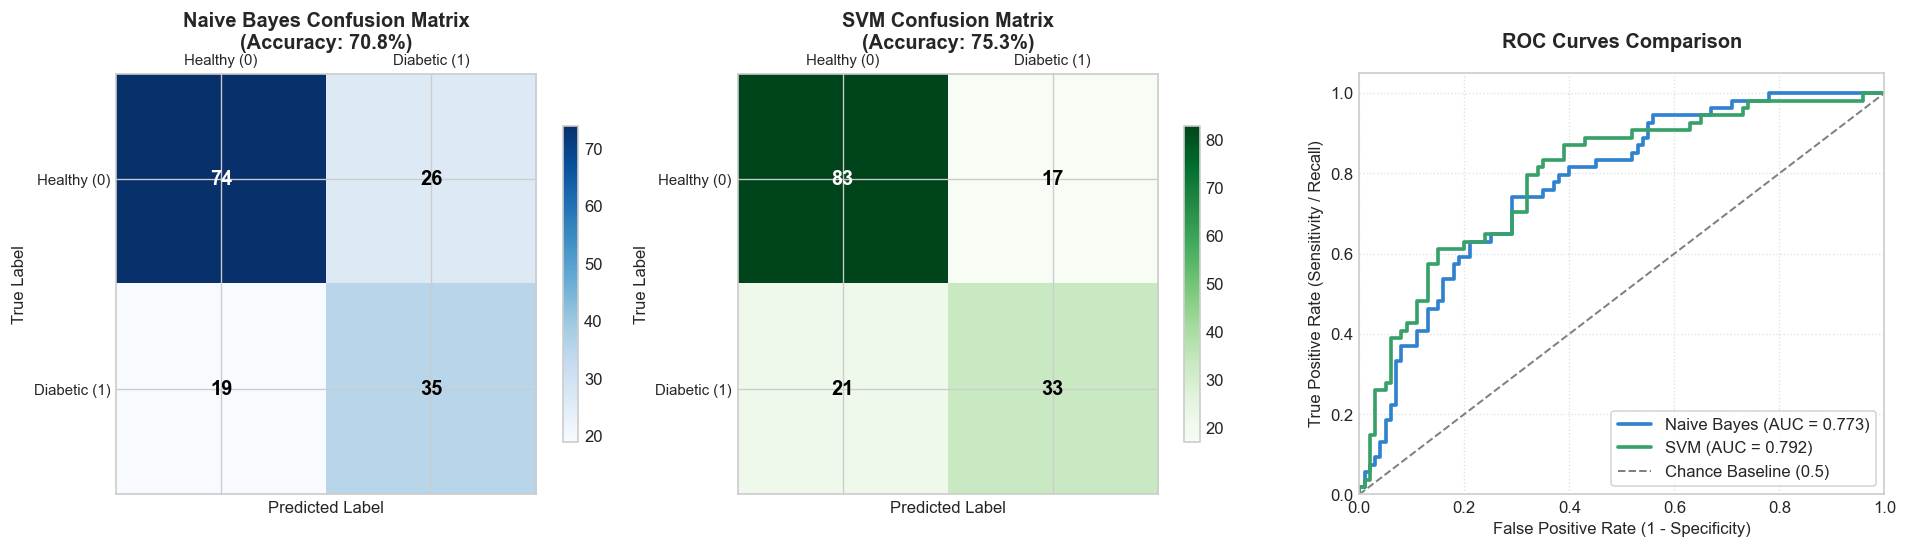

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=120)

# 1. Confusion Matrix - Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)
cax1 = axes[0].matshow(cm_nb, cmap='Blues')
fig.colorbar(cax1, ax=axes[0], shrink=0.75)
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm_nb[i, j]), ha='center', va='center', fontsize=12, fontweight='bold',
                     color='white' if cm_nb[i, j] > cm_nb.max()/2 else 'black')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels([target_names[0], target_names[1]], fontsize=9)
axes[0].set_yticklabels([target_names[0], target_names[1]], fontsize=9)
axes[0].set_title(f"Naive Bayes Confusion Matrix\n(Accuracy: {acc_nb*100:.1f}%)", pad=15, fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# 2. Confusion Matrix - SVM
cm_svm = confusion_matrix(y_test, y_pred_svm)
cax2 = axes[1].matshow(cm_svm, cmap='Greens')
fig.colorbar(cax2, ax=axes[1], shrink=0.75)
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, str(cm_svm[i, j]), ha='center', va='center', fontsize=12, fontweight='bold',
                     color='white' if cm_svm[i, j] > cm_svm.max()/2 else 'black')
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels([target_names[0], target_names[1]], fontsize=9)
axes[1].set_yticklabels([target_names[0], target_names[1]], fontsize=9)
axes[1].set_title(f"SVM Confusion Matrix\n(Accuracy: {acc_svm*100:.1f}%)", pad=15, fontweight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

# 3. ROC Curves Comparison
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
auc_nb = auc(fpr_nb, tpr_nb)
auc_svm = auc(fpr_svm, tpr_svm)

axes[2].plot(fpr_nb, tpr_nb, color='#3182CE', lw=2.2, label=f'Naive Bayes (AUC = {auc_nb:.3f})')
axes[2].plot(fpr_svm, tpr_svm, color='#38A169', lw=2.2, label=f'SVM (AUC = {auc_svm:.3f})')
axes[2].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.2, label='Chance Baseline (0.5)')
axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel("False Positive Rate (1 - Specificity)")
axes[2].set_ylabel("True Positive Rate (Sensitivity / Recall)")
axes[2].set_title("ROC Curves Comparison", pad=15, fontweight='bold')
axes[2].legend(loc="lower right", frameon=True)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### Step 7: Live Inference Demonstration on Unseen Samples
Demonstrate real-time predictions for both algorithms on test samples.


In [8]:
print("=== LIVE INFERENCE PREDICTION DEMO ===")
sample_indices = [0, 5, 12]

for idx in sample_indices:
    raw_sample = X_test.iloc[idx:idx+1]
    scaled_sample = X_test_scaled[idx:idx+1]
    true_label = target_names[int(y_test.iloc[idx])]
    
    pred_nb = target_names[int(nb_model.predict(scaled_sample)[0])]
    prob_nb = nb_model.predict_proba(scaled_sample)[0]
    
    pred_svm = target_names[int(svm_model.predict(scaled_sample)[0])]
    prob_svm = svm_model.predict_proba(scaled_sample)[0]
    
    print(f"\nTest Case #{idx}:")
    print(f" -> True Ground Truth  : [{true_label}]")
    print(f" -> Naive Bayes Output : [{pred_nb}] (Confidence: {max(prob_nb)*100:.1f}%)")
    print(f" -> SVM Output         : [{pred_svm}] (Confidence: {max(prob_svm)*100:.1f}%)")


=== LIVE INFERENCE PREDICTION DEMO ===

Test Case #0:
 -> True Ground Truth  : [Healthy (0)]
 -> Naive Bayes Output : [Diabetic (1)] (Confidence: 51.6%)
 -> SVM Output         : [Diabetic (1)] (Confidence: 75.0%)

Test Case #5:
 -> True Ground Truth  : [Healthy (0)]
 -> Naive Bayes Output : [Healthy (0)] (Confidence: 91.8%)
 -> SVM Output         : [Healthy (0)] (Confidence: 74.9%)

Test Case #12:
 -> True Ground Truth  : [Healthy (0)]
 -> Naive Bayes Output : [Healthy (0)] (Confidence: 94.6%)
 -> SVM Output         : [Healthy (0)] (Confidence: 87.2%)


### Conclusion
1. **Naive Bayes:** Fast, computationally lightweight, and requires zero iterative tuning. However, its conditional independence assumption can slightly degrade performance when predictors have strong covariance.
2. **Support Vector Machine (SVM):** Constructs an optimal maximum-margin hyperplane in high-dimensional kernel space, generally achieving superior boundary separation and higher ROC-AUC when properly regularized ($C$) and scaled.
